# Edge Adaptive Image Steganography Based on LSB Matching Revisited

Weiqi Luo, Fangjun Huang, Jiwu Huang, IEEE TRANSACTIONS ON INFORMATION FORENSICS AND SECURITY, VOL. 5, NO. 2, JUNE 2010

## Overview

The method hides 2 bits in every pair of neighbouring pixels using LSB Matching Revisited (LSBMR). The first bit is the LSB of the first pixel, the second bit is the relation between both pixels.

The embedding is edge adaptive. Only pairs with a large difference between pixels (edges) are used, because edge changes are harder to notice. The difference threshold `T` is chosen from the payload size, so a small payload goes only into sharp edges, a larger one also releases smoother areas. Extraction needs only the modified image and `T`.

The method is not reversible: the original image cannot be restored, only the hidden bits can be extracted.

The paper describes grayscale images. In this approach we will treat each channel (R, G, B) as a separate 8-bit image.

## Data preparation

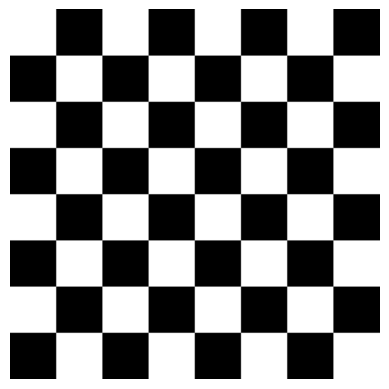

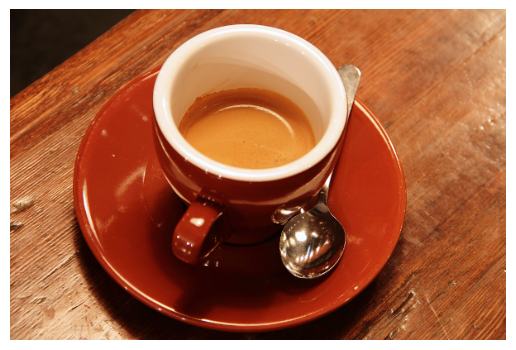

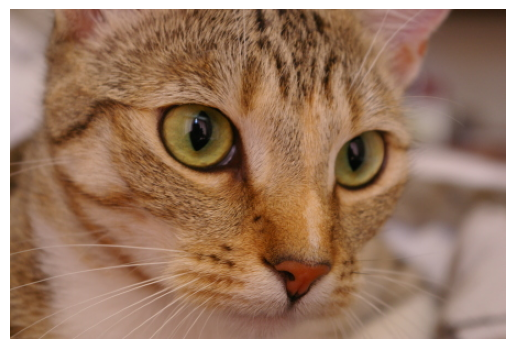

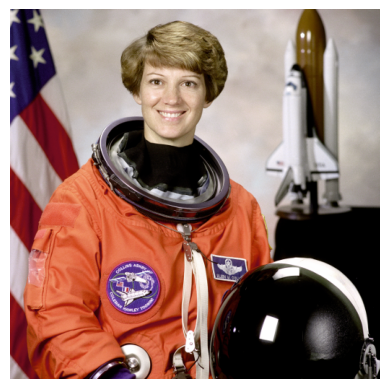

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Implementation

### Pairs and the LSB matching revisited rule

1. Split the flattened channel into non-overlapping units of two consecutive pixels `(x_i, x_i+1)`; if the pixel count is odd, the last pixel is left untouched
2. Hide 2 bits in a unit: the first bit is the LSB of `x_i`, the second bit is the relation `f(x_i, x_i+1) = LSB(floor(x_i / 2) + x_i+1)`
3. Hide bits `(m_i, m_i+1)` by changing at most one pixel by 1:
    - Case 1: `LSB(x_i) = m_i` and `f(x_i, x_i+1) = m_i+1` - nothing to change
    - Case 2: `LSB(x_i) = m_i` and `f(x_i, x_i+1) != m_i+1` - `x_i+1` is changed by random `+1` or `-1`
    - Case 3: `LSB(x_i) != m_i` and `f(x_i - 1, x_i+1) = m_i+1` - `x_i` becomes `x_i - 1`
    - Case 4: `LSB(x_i) != m_i` and `f(x_i - 1, x_i+1) != m_i+1` - `x_i` becomes `x_i + 1`
4. Apply edge adaptation on units with the absolute difference `|x_i - x_i+1| >= T`; `T` is the largest threshold in `[0, 31]` for which the used units can hide the whole payload (2 bits per unit)
5. After the change a unit may leave `[0, 255]` range or its difference may fall below `T`; then the extraction would not find the unit. Such unit is replaced by the closest pair that hides the same two bits, stays in `[0, 255]` range and keeps the difference `>= T`

In [2]:
channel_names = ["R", "G", "B"]
max_threshold = 31

# split channel into pairs of pixels
def split_into_pairs(channel):
    flat = channel.ravel().astype(np.int16)
    return flat[:len(flat) // 2 * 2].reshape(-1, 2)

# second hidden bit - relation between two pixels
def pixel_relation(first_pixel, second_pixel):
    return ((first_pixel // 2) + second_pixel) % 2

# largest threshold for which the pairs with difference >= threshold can hide all bits
def find_threshold(pairs, bit_count):
    differences = np.abs(pairs[:, 0] - pairs[:, 1])
    for threshold in range(max_threshold, -1, -1):
        if 2 * np.sum(differences >= threshold) >= bit_count:
            return threshold
    raise ValueError("payload does not fit into the channel")

In [3]:
pair = (100, 162)
for bits in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    print(f"pair={pair}, LSB={pair[0] % 2}, relation={pixel_relation(*pair)}, bits to hide={bits}")

pair=(100, 162), LSB=0, relation=0, bits to hide=(0, 0)
pair=(100, 162), LSB=0, relation=0, bits to hide=(0, 1)
pair=(100, 162), LSB=0, relation=0, bits to hide=(1, 0)
pair=(100, 162), LSB=0, relation=0, bits to hide=(1, 1)


### Embedding and extraction for one pair

Embedding:
- apply one of the four LSBMR cases to get `(x'_i, x'_i+1)`
- if `x'` is outside `[0, 255]` or `|x'_i - x'_i+1| < T`, search all valid pairs for the one with the same two hidden bits, the difference `>= T` and the smallest distance `|x_i - x*_i| + |x_i+1 - x*_i+1|` to the original pair

Extraction needs only the modified pair and `T`: the bits are `LSB(x_i)` and `f(x_i, x_i+1)`

In [4]:
rng = np.random.default_rng()

# get all possible pixel values of a pair
all_first, all_second = np.meshgrid(np.arange(256), np.arange(256), indexing="ij")

def embed_pair(first_pixel, second_pixel, bits, threshold):
    first_bit, second_bit = bits

    if first_pixel % 2 == first_bit:
        new_first = first_pixel
        if pixel_relation(first_pixel, second_pixel) == second_bit:
            # case 1
            new_second = second_pixel
        else:
            # case 2
            new_second = second_pixel + rng.choice([-1, 1])
    else:
        new_second = second_pixel
        if pixel_relation(first_pixel - 1, second_pixel) == second_bit:
            # case 3
            new_first = first_pixel - 1
        else:
            # case 4
            new_first = first_pixel + 1

    if 0 <= new_first <= 255 and 0 <= new_second <= 255 and abs(new_first - new_second) >= threshold:
        return new_first, new_second

    # readjust - use closest valid pair that hides the same bits
    is_valid = (
        (all_first % 2 == first_bit)
        & (pixel_relation(all_first, all_second) == second_bit)
        & (np.abs(all_first - all_second) >= threshold)
    )
    distance = (np.abs(all_first - first_pixel) + np.abs(all_second - second_pixel)).astype(float)
    distance[~is_valid] = np.inf
    new_first, new_second = np.unravel_index(np.argmin(distance), distance.shape)
    
    return int(new_first), int(new_second)

In [5]:
def extract_pair(first_pixel, second_pixel):
    return [first_pixel % 2, pixel_relation(first_pixel, second_pixel)]

### Embedding and extraction for a channel

The threshold `T` is chosen from the payload size. Pairs with the difference `>= T` are processed in raster order and hide 2 bits each; the last pair is padded with a zero if the payload has an odd length. Extraction uses the same pairs (their difference stays `>= T` after embedding) and stops when all bits are read.

In [6]:
def embed_channel(channel, bits):

    # split channel into pairs of pixels
    pairs = split_into_pairs(channel)

    # choose the threshold - only pairs with difference >= threshold are used
    threshold = find_threshold(pairs, len(bits))

    marked_pairs = pairs.copy()

    # pad an odd payload with one zero, since each pair hides 2 bits
    bits = list(bits) + [0] * (len(bits) % 2)
    embedded_bit_count = 0

    for pair_index, (first_pixel, second_pixel) in enumerate(pairs):
        
        # stop when the whole payload is hidden
        if embedded_bit_count >= len(bits):
            break

        # modify only non-smooth pairs
        if abs(first_pixel - second_pixel) >= threshold:
            # take the next 2 bits and hide them in the current pair
            bits_to_hide = bits[embedded_bit_count:embedded_bit_count + 2]
            marked_pairs[pair_index] = embed_pair(int(first_pixel), int(second_pixel), bits_to_hide, threshold)
            embedded_bit_count += 2

    # put the marked pairs back into the channel
    marked = channel.ravel().copy()
    marked[:marked_pairs.size] = marked_pairs.ravel()
    return marked.reshape(channel.shape), threshold

In [7]:
def extract_channel(marked_channel, threshold, bit_count):
    extracted_bits = []

    for first_pixel, second_pixel in split_into_pairs(marked_channel):
        if len(extracted_bits) >= bit_count:
            break
        if abs(first_pixel - second_pixel) >= threshold:
            extracted_bits += extract_pair(int(first_pixel), int(second_pixel))

    return extracted_bits[:bit_count]

## Usage

Random payload is embedded and extracted for value comparison. Distortion is measured in Peak Signal-to-Noise Ratio (PSNR).

checkerboard  R: capacity=  40000, embedded=  12000, T= 0, PSNR=56.39 dB, recovered=True
checkerboard  G: capacity=  40000, embedded=  12000, T= 0, PSNR=56.36 dB, recovered=True
checkerboard  B: capacity=  40000, embedded=  12000, T= 0, PSNR=56.41 dB, recovered=True
coffee        R: capacity= 240000, embedded=  72000, T= 6, PSNR=57.45 dB, recovered=True
coffee        G: capacity= 240000, embedded=  72000, T= 6, PSNR=57.44 dB, recovered=True
coffee        B: capacity= 240000, embedded=  72000, T= 6, PSNR=57.42 dB, recovered=True
cat           R: capacity= 135300, embedded=  40590, T= 6, PSNR=57.42 dB, recovered=True
cat           G: capacity= 135300, embedded=  40590, T= 6, PSNR=57.43 dB, recovered=True
cat           B: capacity= 135300, embedded=  40590, T= 6, PSNR=57.41 dB, recovered=True
astronaut     R: capacity= 262144, embedded=  78643, T= 5, PSNR=57.41 dB, recovered=True
astronaut     G: capacity= 262144, embedded=  78643, T= 5, PSNR=57.40 dB, recovered=True
astronaut     B: capa

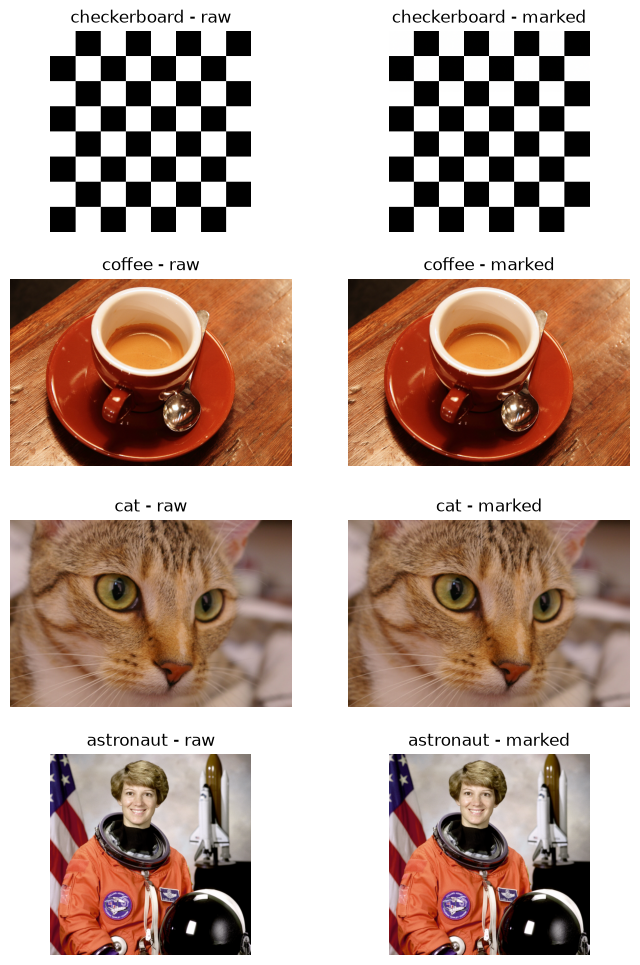

In [8]:
from skimage.metrics import peak_signal_noise_ratio

figure, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 12))

for row, (image_name, image) in enumerate(zip(image_names, imgs_color)):

    marked_channels = []

    for channel_index, channel_name in enumerate(channel_names):
        channel = image[:, :, channel_index]

        # generate random binary payload using 30% of the capacity
        capacity = 2 * len(split_into_pairs(channel))
        bits = rng.integers(0, 2, size=int(0.3 * capacity)).tolist()

        marked, threshold = embed_channel(channel, bits)
        extracted_bits = extract_channel(marked, threshold, len(bits))
        
        marked_channels.append(marked)
        
        recovered = extracted_bits == bits
        psnr = peak_signal_noise_ratio(channel, marked)

        print(f"{image_name:13s} {channel_name}: capacity={capacity:7d}, embedded={len(bits):7d}, T={threshold:2d}, PSNR={psnr:.2f} dB, recovered={recovered}")

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{image_name} - raw")
    axes[row, 1].imshow(np.stack(marked_channels, axis=-1))
    axes[row, 1].set_title(f"{image_name} - marked")

for axis in axes.ravel():
    axis.axis("off")

plt.show()